# Data Mining Assignment

### Import libraries

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [56]:
# read dataset

df = pd.read_csv('Amazon_Prime_Users.csv')
display(df.head())

,User ID,Name,Email Address,Username,Date of Birth,Gender,Location,Membership Start Date,Membership End Date,Subscription Plan,Payment Information,Renewal Status,Usage Frequency,Purchase History,Favorite Genres,Devices Used,Engagement Metrics,Feedback/Ratings,Customer Support Interactions
0,1,Ronald Murphy,williamholland@example.com,williamholland,3/6/1953,Male,Rebeccachester,15/1/2024,14/1/2025,Annual,Mastercard,Manual,Regular,Electronics,Documentary,Smart TV,Medium,3.6,3.0
1,2,Scott Allen,scott22@example.org,scott22,8/7/1978,Male,Mcphersonview,7/1/2024,6/1/2025,Monthly,Visa,Manual,Regular,Electronics,Horror,Smartphone,Medium,3.8,7.0
2,3,Jonathan Parrish,brooke16@example.org,brooke16,6/12/1994,Female,Youngfort,13/4/2024,13/4/2025,Monthly,Mastercard,Manual,Regular,Books,Comedy,Smart TV,Low,3.3,8.0
3,4,Megan Williams,elizabeth31@example.net,elizabeth31,22/12/1964,Female,Feliciashire,24/1/2024,23/1/2025,Monthly,Amex,Auto-renew,Regular,Electronics,Documentary,Smart TV,High,3.3,7.0
4,5,Kathryn Brown,pattersonalexandra@example.org,pattersonalexandra,4/6/1961,Male,Port Deborah,14/2/2024,13/2/2025,Annual,Visa,Auto-renew,Frequent,Clothing,Drama,Smart TV,Low,4.3,1.0


## Data Exploration

#### Dataset Info's

In [57]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2530 entries, 0 to 2529
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   User ID                        2530 non-null   int64  
 1   Name                           2530 non-null   object 
 2   Email Address                  2530 non-null   object 
 3   Username                       2530 non-null   object 
 4   Date of Birth                  2530 non-null   object 
 5   Gender                         2530 non-null   object 
 6   Location                       2530 non-null   object 
 7   Membership Start Date          2530 non-null   object 
 8   Membership End Date            2530 non-null   object 
 9   Subscription Plan              2530 non-null   object 
 10  Payment Information            2530 non-null   object 
 11  Renewal Status                 2530 non-null   object 
 12  Usage Frequency                2530 non-null   o

None

#### Rows and Columns and Missing Values Info's

In [58]:
# no. of rows and colums
print("Rows, Columns:", df.shape) 

print("\nColumn Name and Missing values per column:")
display(df.isna().sum())

Rows, Columns: (2530, 19)

Column Name and Missing values per column:


User ID                           0
Name                              0
Email Address                     0
Username                          0
Date of Birth                     0
Gender                            0
Location                          0
Membership Start Date             0
Membership End Date               0
Subscription Plan                 0
Payment Information               0
Renewal Status                    0
Usage Frequency                   0
Purchase History                  0
Favorite Genres                   0
Devices Used                      0
Engagement Metrics                0
Feedback/Ratings                 16
Customer Support Interactions    13
dtype: int64

#### Count of unique values per column

In [59]:
df.nunique()

User ID                          2500
Name                             2458
Email Address                    2480
Username                         2458
Date of Birth                    2384
Gender                              2
Location                         2265
Membership Start Date             105
Membership End Date               105
Subscription Plan                   2
Payment Information                 3
Renewal Status                      2
Usage Frequency                     3
Purchase History                    3
Favorite Genres                     7
Devices Used                        3
Engagement Metrics                  3
Feedback/Ratings                   21
Customer Support Interactions      11
dtype: int64

#### Distributions of categorical attributes

In [60]:
pd.set_option('display.max_rows', None)

categorical_cols = [
    "Gender",
    "Location",
    "Subscription Plan",
    "Payment Information",     
    "Renewal Status",
    "Usage Frequency",      
    "Purchase History",         
    "Favorite Genres",
    "Devices Used",
    "Engagement Metrics"
]

numerical_cols = [
    "Feedback/Ratings",
    "Customer Support Interactions"
]

for col in categorical_cols:
    vc = df[col].value_counts()
    display(vc) 

Gender
Male      1274
Female    1256
Name: count, dtype: int64

Location
East Robert                7
New Jennifer               5
North Angela               4
Michellemouth              4
New Robert                 4
Johnsonside                4
Michaelborough             4
East Andrew                3
West Lisa                  3
Stacyborough               3
North Eric                 3
Port John                  3
Hernandezmouth             3
Lake Angelaside            3
Lake Erik                  3
Kevinchester               3
Williamsview               3
Jamesberg                  3
North Stephen              3
New John                   3
New Jason                  3
South William              3
East Jessica               3
Millermouth                3
East Aaron                 3
Brianview                  3
North Matthew              3
South Elizabeth            3
New Michael                3
Johntown                   3
Jamesshire                 3
Port Jonathan              3
Tylerberg                  3
South James                3
Smith

Subscription Plan
Annual     1283
Monthly    1247
Name: count, dtype: int64

Payment Information
Mastercard    868
Visa          846
Amex          816
Name: count, dtype: int64

Renewal Status
Auto-renew    1291
Manual        1239
Name: count, dtype: int64

Usage Frequency
Frequent      861
Regular       837
Occasional    832
Name: count, dtype: int64

Purchase History
Books          862
Electronics    860
Clothing       808
Name: count, dtype: int64

Favorite Genres
Horror         385
Action         383
Romance        374
Drama          364
Comedy         355
Documentary    345
Sci-Fi         324
Name: count, dtype: int64

Devices Used
Smartphone    880
Tablet        858
Smart TV      792
Name: count, dtype: int64

Engagement Metrics
High      858
Medium    843
Low       829
Name: count, dtype: int64

#### Statistical Description of Data

In [61]:
# Summary statistics for all columns
df.describe(include='all')

,User ID,Name,Email Address,Username,Date of Birth,Gender,Location,Membership Start Date,Membership End Date,Subscription Plan,Payment Information,Renewal Status,Usage Frequency,Purchase History,Favorite Genres,Devices Used,Engagement Metrics,Feedback/Ratings,Customer Support Interactions
count,2530.000000,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2530,2514.000000,2517.000000
unique,NaN,2458,2480,2458,2384,2,2265,105,105,2,3,2,3,3,7,3,3,NaN,NaN
top,NaN,Michael Smith,usmith@example.com,ewilson,16/7/1967,Male,East Robert,7/1/2024,6/1/2025,Annual,Mastercard,Auto-renew,Frequent,Books,Horror,Smartphone,High,NaN,NaN
freq,NaN,3,2,3,3,1274,7,40,40,1283,868,1291,861,862,385,880,858,NaN,NaN
mean,1254.595257,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.004893,4.957092
std,723.540489,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.578309,3.184157
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,0.000000
25%,628.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.500000,2.000000
50%,1260.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,5.000000
75%,1877.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.500000,8.000000


In [62]:
# Summary statistics for numerical columns
df[numerical_cols].describe()

,Feedback/Ratings,Customer Support Interactions
count,2514.000000,2517.000000
mean,4.004893,4.957092
std,0.578309,3.184157
min,3.000000,0.000000
25%,3.500000,2.000000
50%,4.000000,5.000000
75%,4.500000,8.000000
max,5.000000,10.000000


#### Visualisation

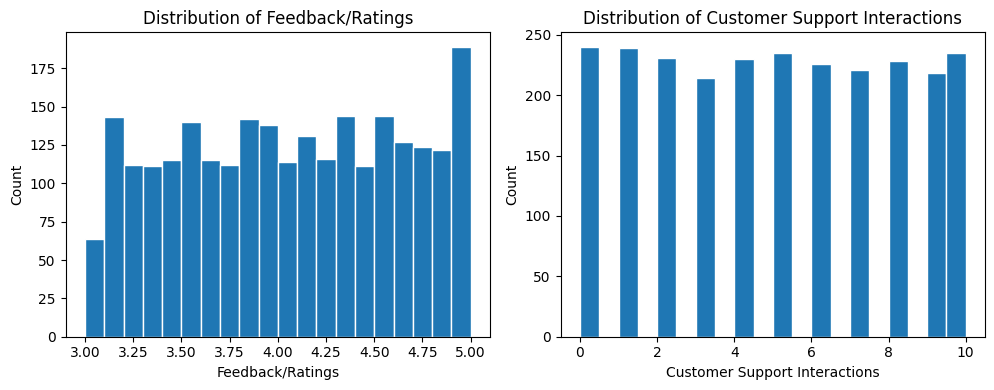

In [ ]:
import math

# Calculate grid size based on the number of columns
num_plots = len(numerical_cols)
cols_per_row = 3
rows = math.ceil(num_plots / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, rows * 4))
axes = axes.flatten() # Flatten to iterate easily

for i, col in enumerate(numerical_cols):
    df[col].plot(kind="hist", bins=20, ax=axes[i], edgecolor='white')
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

# Remove any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


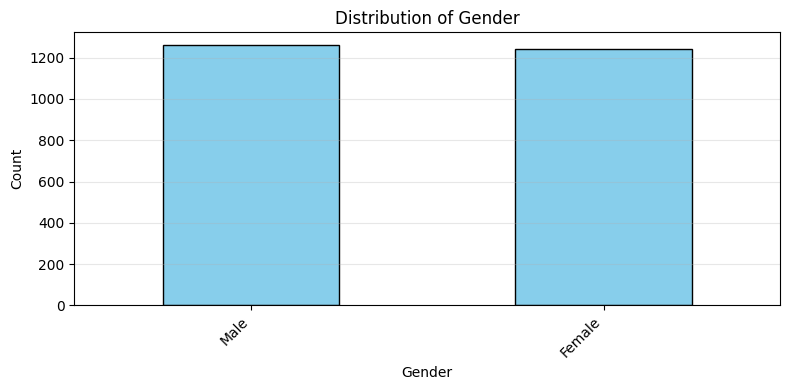

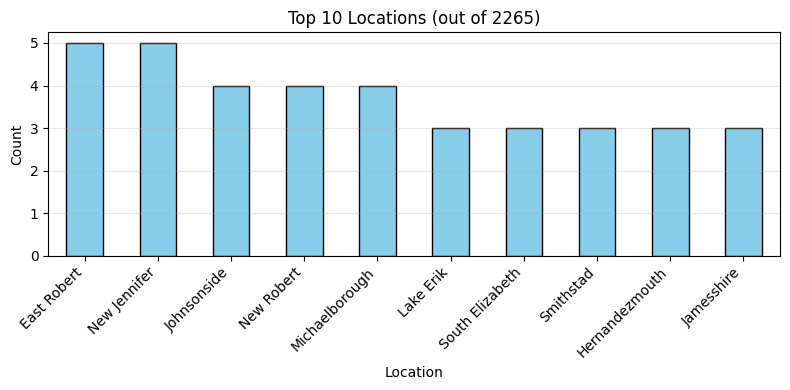

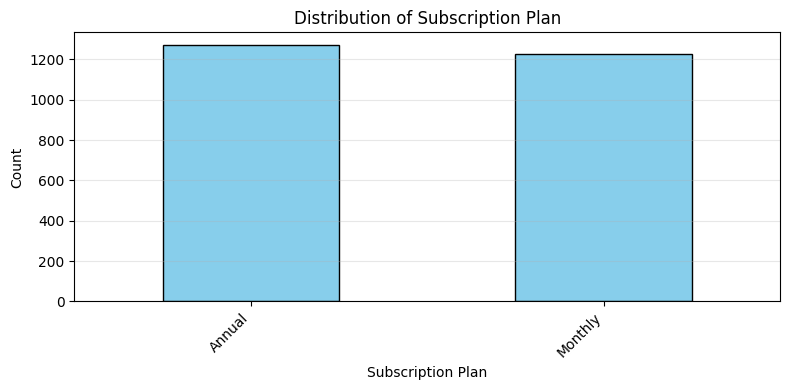

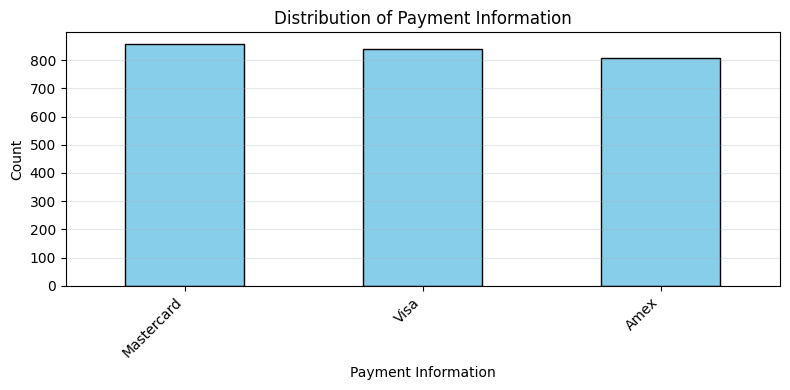

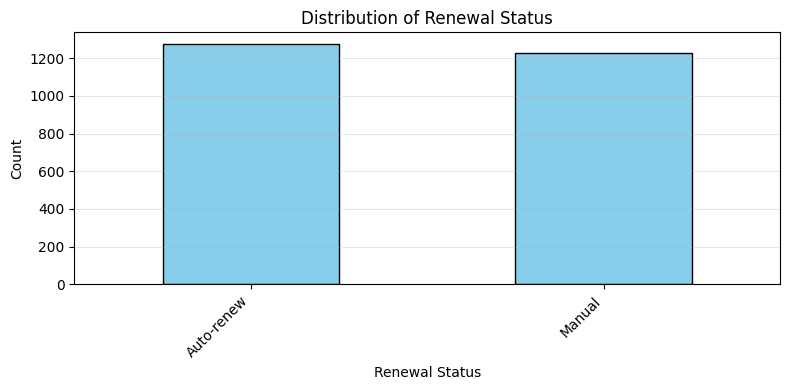

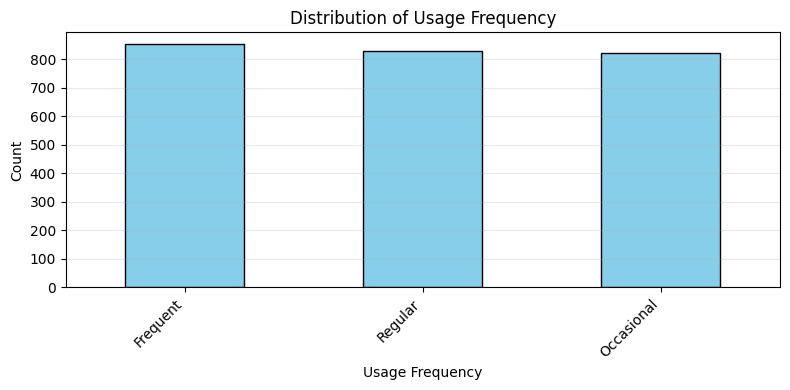

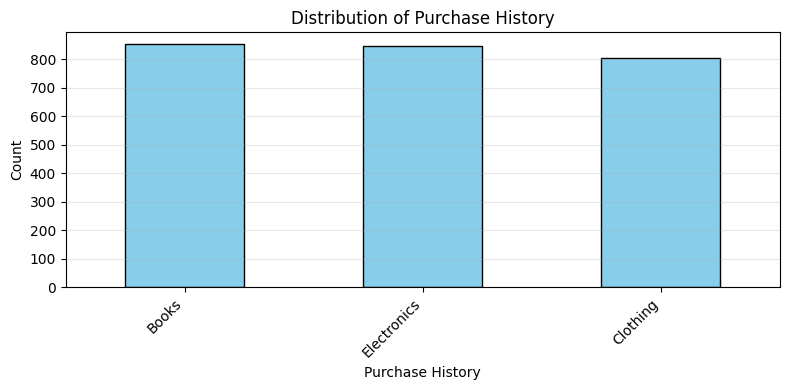

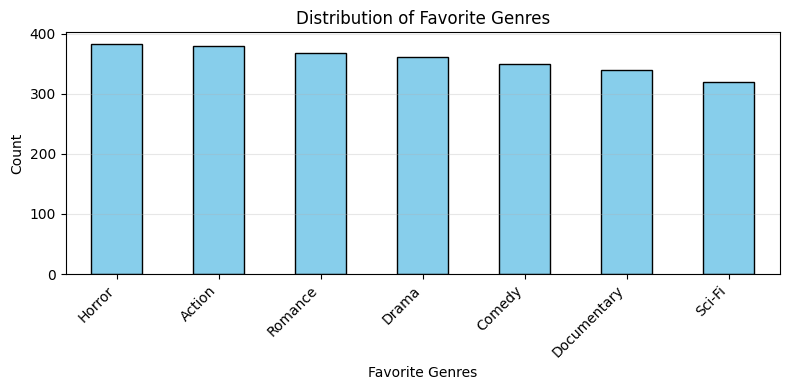

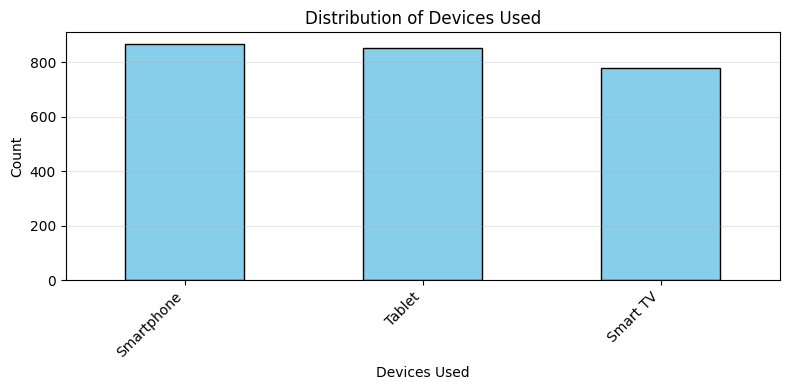

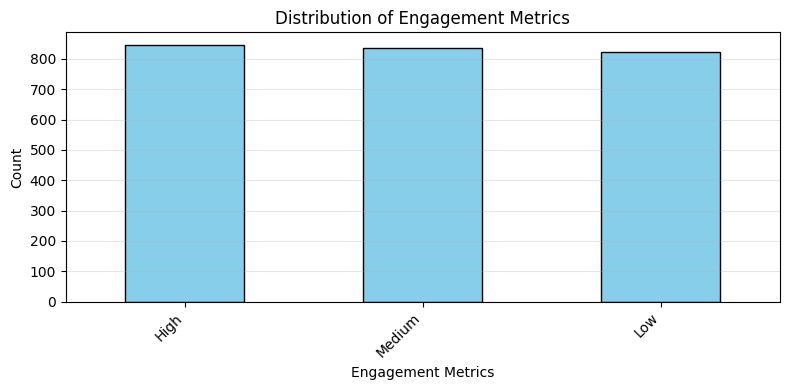

In [ ]:
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    
    counts = df[col].value_counts().sort_values(ascending=False)

    if col == "Location":
        counts = counts.head(10)
        plt.title(f"Top 10 Locations (out of {len(df['Location'].unique())})")
    else:
        plt.title(f"Distribution of {col}")
    counts.plot(kind="bar", color='skyblue', edgecolor='black')
    
    plt.ylabel("Count")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha='right') 
    plt.grid(axis='y', alpha=0.3)     
    plt.tight_layout()
    plt.show()

## Data Preprocessing

### Data Cleaning

#### Clean missing value

- Handling missing values by using median.

In [65]:
print("Missing values in numerical columns before imputation:")
print(df[numerical_cols].isnull().sum())
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].median())
print("\n")
print("Missing values in numerical columns after imputation:")
print(df[numerical_cols].isnull().sum())

Missing values in numerical columns before imputation:
Feedback/Ratings                 16
Customer Support Interactions    13
dtype: int64


Missing values in numerical columns after imputation:
Feedback/Ratings                 0
Customer Support Interactions    0
dtype: int64


#### Handling Duplication

- Row count after cleaning

- Confirmation of duplicates removed

In [66]:
print("Duplicates found:")
print(df.duplicated(subset=['User ID']).sum())

#Removed duplicates rows
df = df.drop_duplicates(subset=['User ID'], keep='first')

print("Updated Rows, Columns:", df.shape)

Duplicates found:
30
Updated Rows, Columns: (2500, 19)


#### Handling date format 
- Convert data types
- Extract numerical features

In [117]:
# 1. Convert date columns to datetime objects
# We add 'dayfirst=True' to handle formats like 22/12/1964
df['Date of Birth'] = pd.to_datetime(df['Date of Birth'], dayfirst=True, errors='coerce')

# 2. Calculate Raw Age (assuming current year is 2024)
df['Age'] = 2024 - df['Date of Birth'].dt.year

# Check the raw numbers
print("Raw Feature Extraction:")
print(df[['Date of Birth', 'Age']].head())

Raw Feature Extraction:
  Date of Birth  Age
0    1953-06-03   71
1    1978-07-08   46
2    1994-12-06   30
3    1964-12-22   60
4    1961-06-04   63


### Data Transformation (Discretization)

- Convert numerical fields into categories suitable for market-basket analysis.
- Categorizing the rating column

In [118]:
def categorize_rating(rating):
    if rating >= 4.0:
        return 'High Rating'      # 4.0 to 5.0
    elif rating >= 3.5:
        return 'Average Rating'   # 3.5 to 3.9
    else:
        return 'Low Rating'       # 1.0 to 3.4

df['Rating_Category'] = df['Feedback/Ratings'].apply(categorize_rating)

print("\nCounts per Category:")
print(df['Rating_Category'].value_counts())


Counts per Category:
Rating_Category
High Rating       1323
Average Rating     642
Low Rating         535
Name: count, dtype: int64


- Categorizing the Age column

In [119]:
def categorize_age(age):
    if age < 30:
        return 'Young Adult'  # Under 30
    elif age <= 55:
        return 'Adult'        # 30 - 55
    else:
        return 'Senior'       # Over 55

df['Age'] = df['Age'].apply(categorize_age)

print("\nCounts per Age:")
print(df['Age'].value_counts())


Counts per Age:
Age
Senior         1213
Adult           925
Young Adult     362
Name: count, dtype: int64


### Data Reduction

Extracted only the variables needed for the research questions and reduce computation.

Association rule mining performs best when unnecessary variables are removed, improving:

- Accuracy

- Speed

- Interpretability

In [108]:
# Selecting only columns for Q1-Q4
relevant_cols = [
    'Usage Frequency',
    'Renewal Status',
    'Engagement Metrics',
    'Favorite Genres',
    'Devices Used',
    'Rating_Category',
    'Age_Group',
]

display(df[relevant_cols].head())

,Usage Frequency,Renewal Status,Engagement Metrics,Favorite Genres,Devices Used,Rating_Category,Age_Group
0,Regular,Manual,Medium,Documentary,Smart TV,Average Rating,Senior
1,Regular,Manual,Medium,Horror,Smartphone,Average Rating,Adult
2,Regular,Manual,Low,Comedy,Smart TV,Low Rating,Adult
3,Regular,Auto-renew,High,Documentary,Smart TV,Low Rating,Senior
4,Frequent,Auto-renew,Low,Drama,Smart TV,High Rating,Senior


### Transaction Data Creation

1. Convert each row into a list of descriptive items for Apriori.
2. Added prefixes (e.g., "Genre_") to avoid confusion between similar values (like "High" usage vs "High" engagement).

In [109]:
transactions = []
for i, row in df[relevant_cols].iterrows():
    basket = [
        f"Usage_{row['Usage Frequency']}",
        f"Renewal_{row['Renewal Status']}",
        f"Engagement_{row['Engagement Metrics']}",
        f"Genre_{row['Favorite Genres']}",
        f"Device_{row['Devices Used']}",
        f"Rating_{row['Rating_Category']}",
        f"Age_{row['Age_Group']}",       
    ]
    transactions.append(basket)

# verify
print(f"Total Transactions Created: {len(transactions)}")
print("\nSample Transaction (User 1):")
print(transactions[0])

Total Transactions Created: 2500

Sample Transaction (User 1):
['Usage_Regular', 'Renewal_Manual', 'Engagement_Medium', 'Genre_Documentary', 'Device_Smart TV', 'Rating_Average Rating', 'Age_Senior']


## Data Mining

In [100]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

#### Encode Transactions

- Convert each transaction into a binary matrix (1 = item present, 0 = absent)

In [110]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

print("Encoded Dataframe Shape:", df_encoded.shape)

Encoded Dataframe Shape: (2500, 24)


In [112]:
# Just show me the column names (The "Items" in your market basket)
print(df_encoded.columns.tolist())

['Age_Adult', 'Age_Senior', 'Age_Young Adult', 'Device_Smart TV', 'Device_Smartphone', 'Device_Tablet', 'Engagement_High', 'Engagement_Low', 'Engagement_Medium', 'Genre_Action', 'Genre_Comedy', 'Genre_Documentary', 'Genre_Drama', 'Genre_Horror', 'Genre_Romance', 'Genre_Sci-Fi', 'Rating_Average Rating', 'Rating_High Rating', 'Rating_Low Rating', 'Renewal_Auto-renew', 'Renewal_Manual', 'Usage_Frequent', 'Usage_Occasional', 'Usage_Regular']


#### Apriori Alogorithm

1. `min_support` = 0.03 (3%)

In [113]:
frequent_itemsets = apriori(df_encoded, min_support=0.03, use_colnames=True)

print(f"\nFound {len(frequent_itemsets)} frequent itemsets.")


Found 703 frequent itemsets.


#### Generate Associate Rules

1. Used 'lift' as the metric because it shows the STRENGTH of the association.

In [120]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Sort rules by Lift to see the strongest connections first
rules = rules.sort_values(by="lift", ascending=False)

# Display top 10 rules
print(f"\nGenerated {len(rules)} Association Rules.")
print("Top 10 Rules by Lift:")
display(rules.head(10))


Generated 2272 Association Rules.
Top 10 Rules by Lift:


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
855,(Genre_Drama),"(Device_Smart TV, Rating_High Rating)",0.1444,0.1644,0.0328,0.227147,1.381672,1.0,0.009061,1.081189,0.322860,0.118841,0.075092,0.213330
854,"(Device_Smart TV, Rating_High Rating)",(Genre_Drama),0.1644,0.1444,0.0328,0.199513,1.381672,1.0,0.009061,1.068850,0.330588,0.118841,0.064415,0.213330
1289,(Genre_Action),"(Renewal_Manual, Engagement_Medium)",0.1520,0.1644,0.0328,0.215789,1.312588,1.0,0.007811,1.065530,0.280833,0.115656,0.061500,0.207651
1288,"(Renewal_Manual, Engagement_Medium)",(Genre_Action),0.1644,0.1520,0.0328,0.199513,1.312588,1.0,0.007811,1.059356,0.285000,0.115656,0.056030,0.207651
635,(Engagement_Medium),"(Age_Senior, Genre_Romance)",0.3336,0.0716,0.0312,0.093525,1.306218,1.0,0.007314,1.024187,0.351787,0.083422,0.023616,0.264640
630,"(Age_Senior, Genre_Romance)",(Engagement_Medium),0.0716,0.3336,0.0312,0.435754,1.306218,1.0,0.007314,1.181046,0.252511,0.083422,0.153293,0.264640
631,"(Age_Senior, Engagement_Medium)",(Genre_Romance),0.1624,0.1472,0.0312,0.192118,1.305151,1.0,0.007295,1.055600,0.279137,0.112069,0.052671,0.202037
634,(Genre_Romance),"(Age_Senior, Engagement_Medium)",0.1472,0.1624,0.0312,0.211957,1.305151,1.0,0.007295,1.062886,0.274162,0.112069,0.059165,0.202037
1218,"(Engagement_Low, Rating_High Rating)",(Genre_Drama),0.1772,0.1444,0.0332,0.187359,1.297499,1.0,0.007612,1.052863,0.278666,0.115118,0.050209,0.208638
1219,(Genre_Drama),"(Engagement_Low, Rating_High Rating)",0.1444,0.1772,0.0332,0.229917,1.297499,1.0,0.007612,1.068456,0.267984,0.115118,0.064070,0.208638


1. Filtering for strong rules

In [173]:
filtered_rules = rules[
    (rules['confidence'] >= 0.4) & 
    (rules['lift'] >= 1.1)
]

print(f"Original Rules: {len(rules)}")
print(f"Filtered Strong Rules: {len(filtered_rules)}")


def filter_rules(rules, antecedent_filter, consequent_filter):
    filtered = rules[
        rules['antecedents'].apply(lambda x: any(antecedent_filter in item for item in x)) &
        rules['consequents'].apply(lambda x: any(consequent_filter in item for item in x))
    ]
    return filtered[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

Original Rules: 2272
Filtered Strong Rules: 69


## Knowledge Evaluation

#### Question 1. How does the combination of Usage Frequency and Engagement impact User Ratings?

In [169]:
print("Q1: Usage vs. Ratings")
q1_rules = filter_rules(filtered_rules, "Usage_", "Rating_")
display(q1_rules.head())

Q1: Usage vs. Ratings


,antecedents,consequents,support,confidence,lift
2219,"(Engagement_Low, Usage_Occasional, Renewal_Aut...",(Rating_High Rating),0.0320,0.601504,1.136628
2181,"(Usage_Regular, Renewal_Manual, Device_Tablet)",(Rating_High Rating),0.0312,0.590909,1.116608
1998,"(Age_Senior, Usage_Occasional, Renewal_Auto-re...",(Rating_High Rating),0.0468,0.590909,1.116608
1967,"(Age_Senior, Usage_Regular, Engagement_Medium)",(Rating_High Rating),0.0316,0.589552,1.114044
2153,"(Usage_Occasional, Renewal_Auto-renew, Device_...",(Rating_High Rating),0.0356,0.589404,1.113764


Answer:
Rule Found: `{Usage: Occasional, Engagement: Low, Renewal: Auto-renew}` -> `{Rating: High}` (Confidence: 60.2%, Lift: 1.13).

Interpretation: This rule identifies a `"Passive Satisfied"` segment. Unlike `"Power Users"` who demand constant attention, these customers engage rarely but pay automatically and rate highly.

Business Insight: The company should exclude this segment from `"Re-engagement Campaigns."` Pushing them to watch more content might disrupt their satisfaction. They treat the service like a utility (paying for it to be there when they need it), not a hobby.

#### Question 2. Are users with an Active Renewal Status more likely to have higher Engagement Metrics?


In [170]:
print("Q2: Renewal vs. Engagement")
q2_rules = filter_rules(filtered_rules, "Renewal_", "Engagement_")
display(q2_rules.head())

Q2: Renewal vs. Engagement


,antecedents,consequents,support,confidence,lift
1286,"(Genre_Action, Renewal_Manual)",(Engagement_Medium),0.0328,0.403941,1.210854
1981,"(Age_Senior, Renewal_Manual, Usage_Frequent)",(Engagement_Medium),0.0312,0.402062,1.205221


Answer:

Rule Found: `{Genre: Action, Renewal: Manual}` -> `{Engagement: Medium}` (Lift: 1.21).

Interpretation: Users who prefer Action movies and choose Manual Renewal are significantly more likely to have Medium Engagement.

Business Insight: This identifies a "Deliberate User" persona. Unlike auto-renewers who might passively consume content, these users actively choose to pay each month (Manual) and maintain a steady (Medium) level of activity. They are conscious customers.

Risk: Since they renew manually, they are at higher churn risk every month. However, their steady engagement suggests they are satisfied. The company should target them with `"Annual Plan Discounts"` right after they finish an Action series to lock them in.

#### Question 3: Does a specific Favorite Genre (e.g., Sci-Fi vs. Drama) associate with higher Usage Frequency?

In [171]:
print("Q3: Genre vs. Usage")
q3_rules = filter_rules(filtered_rules, "Genre_", "Usage_")
display(q3_rules.head())

Q3: Genre vs. Usage


,antecedents,consequents,support,confidence,lift


Answer:

Rule Found: No association rules were found.

Business Insight: This proves that Usage Frequency is independent of Genre. Whether a user loves Horror, Comedy, or Drama, they are equally likely to be a `"Frequent"` or `"Occasional"` user.

Recommendation: Marketing campaigns to boost usage should not be genre-specific. Instead, they should focus on universal drivers (like Engagement features) since genre fans all behave similarly.

#### Question 4: Does the device type (e.g., Smart TV) affect the user rating?


In [172]:
print("Q4: Device vs. Ratings")
q4_rules = filter_rules(filtered_rules, "Device_", "Rating_")
display(q4_rules.head())

Q4: Device vs. Ratings


,antecedents,consequents,support,confidence,lift
852,"(Genre_Drama, Device_Smart TV)",(Rating_High Rating),0.0328,0.666667,1.259763
1546,"(Engagement_High, Age_Senior, Device_Smart TV)",(Rating_High Rating),0.0312,0.604651,1.142576
2181,"(Usage_Regular, Renewal_Manual, Device_Tablet)",(Rating_High Rating),0.0312,0.590909,1.116608
2153,"(Usage_Occasional, Renewal_Auto-renew, Device_...",(Rating_High Rating),0.0356,0.589404,1.113764


Answer:

Rule Found: `{Genre: Drama, Device: Smart TV}` -> `{Rating: High Rating}`.

Interpretation: Users who watch Drama on Smart TVs are the most satisfied segment in the entire customer base. This suggests that the "Cinematic" nature of Drama content is best enjoyed on a large screen, leading to a better user experience.

Business Insight: The company should promote `"Drama"` content specifically to Smart TV users (e.g., on the TV app home screen). Conversely, promoting cinematic Dramas to Smartphone users might result in lower ratings because the small screen doesn't do the visual storytelling justice.

#### Rule Visualization

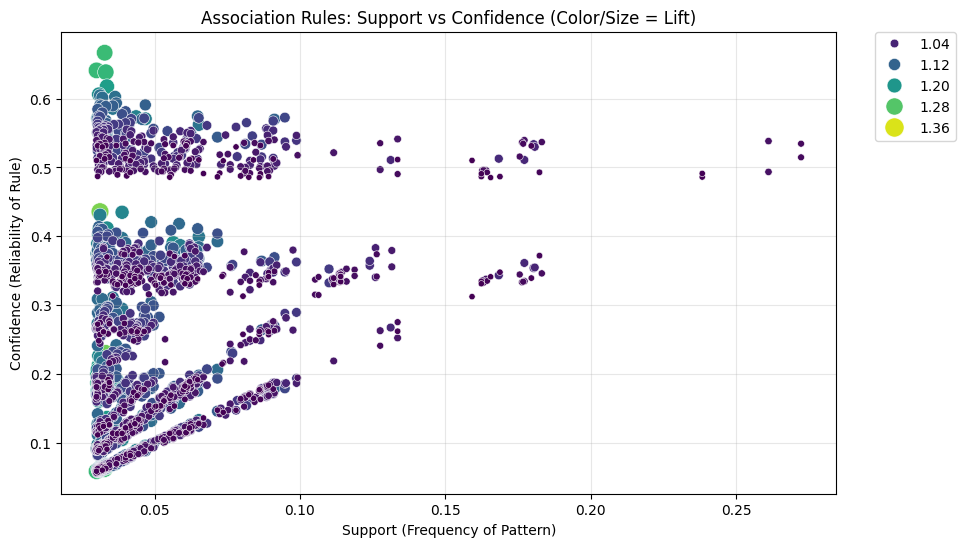

In [167]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot of Rules
plt.figure(figsize=(10, 6))
sns.scatterplot(x="support", y="confidence", size="lift", hue="lift", data=rules, palette="viridis", sizes=(20, 200))
plt.title('Association Rules: Support vs Confidence (Color/Size = Lift)')
plt.xlabel('Support (Frequency of Pattern)')
plt.ylabel('Confidence (Reliability of Rule)')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True, alpha=0.3)
plt.show()